# 04 · Step 0: the acquisition

The first thing drawn for an image is the **simulated scan**: its resolution (voxel spacing),
slice thickness and contrast. It is drawn first because two later steps use it:

* **step 4** (tree intensities): the coarsest spacing decides which tree nodes are visible
  (notebook 02); labels the scan cannot resolve share one Gaussian;
* **step 5c** (resolution): the image is blurred and resampled to this acquisition (notebook 09).

Code: `nxgen/online/acquisition.py`. Config section: `acquisition`.

In [2]:
from _setup import *
from nxgen.online import acquisition as A
from nxgen.core.config import load_config

## 1. The priors (SynthSeg, Billot et al. 2023, Sec. 3.1.4)

With `r` the output voxel size (`grid.target_voxel_mm`):

| probability | mode | spacing |
|---|---|---|
| `1 - lowres_prob` | `none` | `r` on every axis (no degradation) |
| `lowres_prob * iso_prob` | `iso` | `U(r, max_iso_mm)`, the same on the 3 axes |
| `lowres_prob * (1 - iso_prob)` | `aniso` | one random axis `U(r, max_aniso_mm)`, the others `r` |

<div class="alert alert-warning">
<strong>Warning:</strong> aniso prob always set 2 axis with r, maybe completly random is better.
</div>

On every degraded axis:

* **thickness** `~ U(r, spacing)` if `random_thickness` (a slice gap), else `= spacing` (eq. 21);
* **alpha** `~ U(alpha)`: a random deviation of the nominal profile (eq. 22);
* **slice-profile std**, in output voxels (eq. 23):

$$\sigma = \frac{2\,\alpha\,\log 10}{2\pi}\;\frac{\text{thickness}}{r}$$

  (the signal power is divided by 10 at the cut-off frequency of the slice).

The **contrast** is drawn from `contrasts` (if given) and is used for the per-contrast `r_max`
of the tree.

In [9]:
cfg = load_config(acquisition=dict(lowres_prob=0.9, iso_prob=0.2, max_iso_mm=3.0,
                                   max_aniso_mm=6.0, contrasts=['T1', 'T2', 'FLAIR']))['acquisition']
# cfg = load_config(acquisition=dict(lowres_prob=0.9, iso_prob=0.2, max_iso_mm=3.0,
#                                    max_aniso_mm=6.0, contrasts=None))['acquisition']
print(cfg)
rng = np.random.default_rng(0)
one = A.sample(cfg, rng, voxel_mm=1.0)
print(one)
print(A.describe(one, voxel_mm=1.0))

{'lowres_prob': 0.9, 'iso_prob': 0.2, 'max_iso_mm': 3.0, 'max_aniso_mm': 6.0, 'alpha': [0.970873786407767, 1.03], 'random_thickness': True, 'contrasts': ['T1', 'T2', 'FLAIR']}
{'spacing_mm': [1.0330552710570582, 1.0330552710570582, 1.0330552710570582], 'thickness_mm': [1.0268828681994036, 1.0200525100008928, 1.0179696714462805], 'alpha': [1.0248415676273914, 1.0140061558873064, 1.0261610782608497], 'contrast': 'FLAIR'}
('iso', [0, 1, 2])


The returned dict is what goes into `plan['acquisition']`. It holds only physical values, the
single source of truth:

| key | meaning |
|---|---|
| `spacing_mm` | slice spacing per axis; an axis is **degraded** when it is larger than the output voxel |
| `thickness_mm`, `alpha` | slice thickness and profile factor per axis (ignored on non-degraded axes) |
| `contrast` | the contrast, or `None` |

Everything else is derived when needed:

| function | returns |
|---|---|
| `degraded_axes(acq, r)` | the degraded axes |
| `describe(acq, r)` | `(mode, axes)`: `'none'`, `'iso'`, `'aniso'`, or `'custom'` (hand-edited combinations `sample` never draws) |
| `sigma_vox(acq, r)` | std of the slice profile per axis, in output voxels (0 = not degraded) |

`acq = None` (e.g. `plan['acquisition'] = None`) means not degraded.

## 2. The distributions, from 20 000 draws

{'none': 0.1, 'iso': 0.181, 'aniso': 0.719, 'custom': 0.0}  expected: {'none': 0.1, 'iso': 0.18000000000000002, 'aniso': 0.7200000000000001, 'custom': 0}


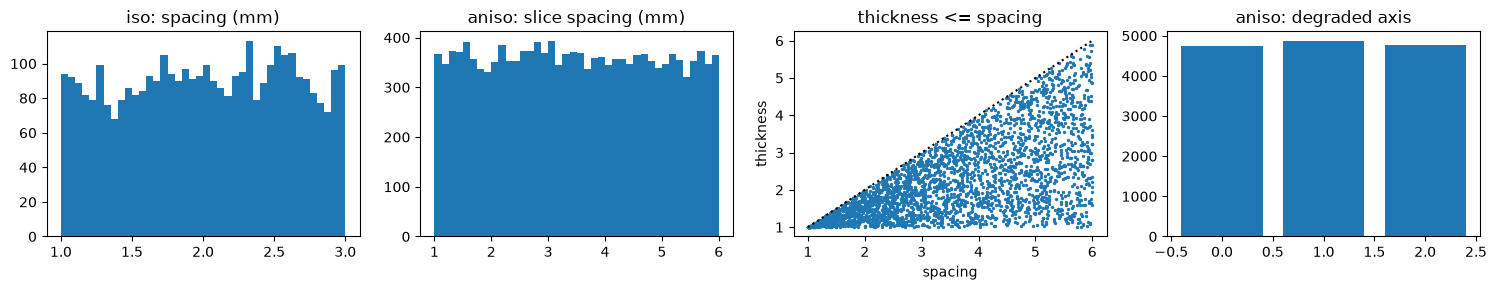

contrasts: {'T1': 6605, 'T2': 6704, 'FLAIR': 6691}


In [10]:
draws = [A.sample(cfg, rng, 1.0) for _ in range(20000)]
desc = [A.describe(d, 1.0) for d in draws]               # (mode, degraded axes)
modes = [m for m, _ in desc]
print({m: round(modes.count(m) / len(modes), 3) for m in ('none', 'iso', 'aniso', 'custom')},
      ' expected:', {'none': 0.1, 'iso': 0.9 * 0.2, 'aniso': 0.9 * 0.8, 'custom': 0})

fig, ax = plt.subplots(1, 4, figsize=(15, 3))
iso = [d['spacing_mm'][0] for d, m in zip(draws, modes) if m == 'iso']
aniso = [(d, axes[0]) for d, (m, axes) in zip(draws, desc) if m == 'aniso']
ax[0].hist(iso, 40); ax[0].set_title('iso: spacing (mm)')
ax[1].hist([d['spacing_mm'][a] for d, a in aniso], 40); ax[1].set_title('aniso: slice spacing (mm)')
th = [(d['spacing_mm'][a], d['thickness_mm'][a]) for d, a in aniso]
ax[2].scatter(*zip(*th[:3000]), s=2); ax[2].plot([1, 6], [1, 6], 'k:')
ax[2].set_xlabel('spacing'); ax[2].set_ylabel('thickness'); ax[2].set_title('thickness <= spacing')
ax[3].hist([a for _, a in aniso], bins=[-.5, .5, 1.5, 2.5], rwidth=.8)
ax[3].set_title('aniso: degraded axis')
plt.tight_layout(); plt.show()
print('contrasts:', {c: sum(d['contrast'] == c for d in draws) for c in cfg['contrasts']})

## 3. The slice profile

`slice_sigma_vox(thickness, alpha, voxel)` is eq. 23; `sigma_vox(acq, voxel)` applies it to every
degraded axis of an acquisition (it is not stored in the plan: the renderer computes it, so
editing `thickness_mm` or `alpha` changes the image). A 3 mm slice on a 1 mm grid has a Gaussian
profile of std ≈ 2.2 voxels (FWHM ≈ 5.2 voxels): the blur is wider than the thickness, which
avoids aliasing when the image is downsampled.

In [11]:
for t in (1.0, 2.0, 3.0, 5.0):
    s = A.slice_sigma_vox(t, 1.0, 1.0)
    print(f'thickness {t} mm -> sigma {s:.2f} voxels (FWHM {2.3548 * s:.2f})')

thickness 1.0 mm -> sigma 0.73 voxels (FWHM 1.73)
thickness 2.0 mm -> sigma 1.47 voxels (FWHM 3.45)
thickness 3.0 mm -> sigma 2.20 voxels (FWHM 5.18)
thickness 5.0 mm -> sigma 3.66 voxels (FWHM 8.63)


## 4. Settings of the NextBrain config

In `configs/nextbrain.json` (0.4 mm output), half of the images are degraded, and only up to
1 mm:

{'lowres_prob': 0.5, 'iso_prob': 0.2, 'max_iso_mm': 1.0, 'max_aniso_mm': 1.0, 'alpha': [0.970873786407767, 1.03], 'random_thickness': True, 'contrasts': None}


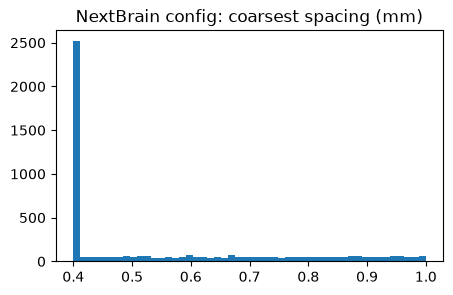

In [12]:
cfg_nb = load_config(CONFIG)['acquisition']
print(cfg_nb)
d = [A.sample(cfg_nb, rng, 0.4) for _ in range(5000)]
coarsest = [max(x['spacing_mm']) for x in d]
plt.figure(figsize=(5, 3)); plt.hist(coarsest, 50)
plt.title('NextBrain config: coarsest spacing (mm)'); plt.show()

Remember notebook 02: the NextBrain tree has 298 generation classes at 0.4 mm but only 34 at
0.6 mm. With these settings, a large share of the images collapse most of the fine labels,
by design: the scan cannot show them.

## 5. Edge cases and pinning

* If `max_iso_mm` (or `max_aniso_mm`) is not larger than `r`, that mode returns `none`.
* `lowres_prob = 0` → always `none`; `lowres_prob = 1, iso_prob = 0` → always one thick axis.
* The random numbers are always drawn in the same order (contrast first), so the contrast of an
  image does not depend on whether it was degraded.
* To remove the degradation of one image: `plan['acquisition'] = None`.
* To force a specific acquisition for one image, edit the physical values of the plan.
  `none_params(r)` gives a non-degraded acquisition to start from:

In [13]:
fixed = dict(A.none_params(0.4, contrast='T1'),
             spacing_mm=[0.4, 0.4, 4.0], thickness_mm=[0.4, 0.4, 3.0], alpha=[1, 1, 1])
print(fixed)
print('derived:', A.describe(fixed, 0.4), 'sigma_vox', [round(s, 2) for s in A.sigma_vox(fixed, 0.4)])

{'spacing_mm': [0.4, 0.4, 4.0], 'thickness_mm': [0.4, 0.4, 3.0], 'alpha': [1, 1, 1], 'contrast': 'T1'}
derived: ('aniso', [2]) sigma_vox [0.0, 0.0, 5.5]


Notebook 09 shows how this acquisition degrades the image, and notebook 08 how it changes the
intensities.